#### 1. Setup 




In [1]:
from dotenv import load_dotenv
import os

load_dotenv()
os.getenv("GROQ_API_KEY")
a = 10
a


10

In [2]:
import truststore
truststore.inject_into_ssl()

from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-20b")

In [3]:
res = llm.invoke("Capital of france?")
res.content

'The capital of France is **Paris**.'

### 2. State - Global State to pass the data between all the nodes

In [4]:
from pydantic import BaseModel

class UserState(BaseModel):
    name: str = ""
    age: int = 0
    email: str = ""

state = UserState(name="Chetan")

state

UserState(name='Chetan', age=0, email='')

##### 2.1 Building the Graph Using Langgraph

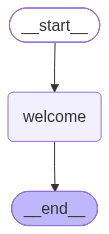

In [5]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel

class MyState(BaseModel):
    messages: str = ""
    isPassed: bool = False

def greet(state: MyState):
    "I am greet node..."
    print("[NODE: ] GREET (BEFORE changing msg in state is): ", state.messages)
    state.isPassed = True
    state.messages = "Goodmorning !"
    print("[NODE: ] GREET (AFTER changing msg in state is): ", state.messages)
    return state

graph = StateGraph(MyState)
graph.add_node("welcome", greet)
graph.add_edge(START, "welcome")
graph.add_edge("welcome", END)

final_graph = graph.compile()
final_graph

In [6]:
res = final_graph.invoke({"messages": "Hello, How are you ?"})
res

[NODE: ] GREET (BEFORE changing msg in state is):  Hello, How are you ?
[NODE: ] GREET (AFTER changing msg in state is):  Goodmorning !


{'messages': 'Goodmorning !', 'isPassed': True}

##### 2.2 Multinode Graph

In [7]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel
from random import randint
#randint(10, 23)

# Step 1: Create a class for state object. A pydantic BaseModel class
class ReviewState(BaseModel):
    text: str = ""
    score: int = 0
    comments: str = ""

# Step 2: Create Node 2 (Because langraph's START is the first node in the graph)
def score(state: ReviewState) -> ReviewState:
    state.score = randint(1, 10)
    return state

# Step 3: Create Node 3
def commenter(state: ReviewState) -> ReviewState:
    if state.score > 5:
        state.comments = "Well Done"
    else:
        state.comments = "Needs Improvement"
    return state

# Step 4: Create a graph using the StateGraph of langgraph.graph module.
graph = StateGraph(ReviewState)

# Step 5: Add nodes to the graph
graph.add_node("score", score)
graph.add_node("commenter", commenter)

# Step 6: Add edges to the graph
graph.add_edge(START, "score")
graph.add_edge("score", "commenter")
graph.add_edge("commenter", END)

# Step 7: Compile & Print the graph
final_graph = graph.compile()
final_graph

# Step 8: Invoke the graph with initial state
res = final_graph.invoke({})
res


{'text': '', 'score': 9, 'comments': 'Well Done'}

#### 3. `add_messages` reducer - for chat history

In [8]:
from langgraph.graph.message import add_messages
from typing import Annotated

# add_messages is a inbuilt reducer. Reducers are used to add items in list.
# It will keep the existing items in the list and add new items to it.
class ChatState(BaseModel):
    messages: Annotated[list, add_messages()] = []

def custom_reducer(existing_item: list, new_item: list) -> list:
    # Custom logic to combine existing and new items
    all_items = existing_item + new_item

    # Try this and see output in the final graph without custom reducer.
    # Uncomment the below line and comment the below retunr statement to see the difference in output.
    # return all_items[-1:] # Keep only the last item

    # Try this and see output in the final graph with custom reducer.
    # Uncomment the below line and comment the above line to see the difference in output.
    return all_items # Keep all items

class ChatStateWithCustomReducer(BaseModel):
    messages: Annotated[list, custom_reducer] = []

def chat_bot(state: ChatState | ChatStateWithCustomReducer) -> ChatState | ChatStateWithCustomReducer:
    #print(state.messages)
    if type(state) == ChatStateWithCustomReducer:
        state.messages = [llm.invoke(state.messages)]
    else:
        state.messages = llm.invoke(state.messages)
    return state

graph = StateGraph(ChatState)

graph.add_node("chat_bot", chat_bot)
graph.add_edge(START, "chat_bot")
graph.add_edge("chat_bot", END)

final_graph = graph.compile()
final_graph
res = final_graph.invoke({"messages": [{"role": "user", "content": "Hello, How are you ?"}]})
res
#res_with_custom_reducer = final_graph_with_custom_reducer.invoke({"messages": [{"role": "user", "content": "Hello, How are you ? I am calling you using a custom reducer."}]})
#res_with_custom_reducer


{'messages': [HumanMessage(content='Hello, How are you ?', additional_kwargs={}, response_metadata={}, id='a5ede9df-4678-4eb9-8754-f34e88a567a9'),
  AIMessage(content="Hello! I'm just a program, so I don't have feelings, but I'm here and ready to help. What can I do for you today?", additional_kwargs={'reasoning_content': 'The user says "Hello, How are you ?" This is a greeting. We should respond politely. Probably "Hello! I\'m an AI, so I don\'t have feelings, but I\'m here to help. How can I assist you today?" That is typical.'}, response_metadata={'token_usage': {'completion_tokens': 90, 'prompt_tokens': 77, 'total_tokens': 167, 'completion_time': 0.092531922, 'completion_tokens_details': {'reasoning_tokens': 52}, 'prompt_time': 0.003741157, 'prompt_tokens_details': None, 'queue_time': 0.383235552, 'total_time': 0.096273079}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_816fc87d18', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provi

In [9]:
graph_with_custom_reducer = StateGraph(ChatStateWithCustomReducer)
graph_with_custom_reducer.add_node("chat_bot", chat_bot)
graph_with_custom_reducer.add_edge(START, "chat_bot")
graph_with_custom_reducer.add_edge("chat_bot", END)
final_graph_with_custom_reducer = graph_with_custom_reducer.compile()
final_graph_with_custom_reducer
final_graph_with_custom_reducer.invoke({"messages": [{"role": "user", "content": "Hello, How are you ? I am calling you using a custom reducer."}]})

{'messages': [{'role': 'user',
   'content': 'Hello, How are you ? I am calling you using a custom reducer.'},
  AIMessage(content='Hello! I’m doing well—thanks for asking. How can I help you today? I noticed you mentioned a “custom reducer.” Are you working on a specific project or framework (e.g., Redux, state management in React, or something else) and need some guidance on how to set it up or troubleshoot it? Let me know what you’re trying to achieve, and I’ll do my best to assist!', additional_kwargs={'reasoning_content': 'The user says: "Hello, How are you ? I am calling you using a custom reducer." They greet and mention "custom reducer". We need to respond accordingly. The user might be using some custom code to call the assistant. We should respond politely, ask about the custom reducer, maybe provide assistance. We need to adhere to policy: no disallowed content. It\'s just a greeting. We can ask how we can help. Also mention we are fine. We can ask what they need. Provide he

#### 4. Routing - Langgraph Core Component

##### Use case is - build a ecommerce agent that will solve billing, refund and order status related problems for the customers

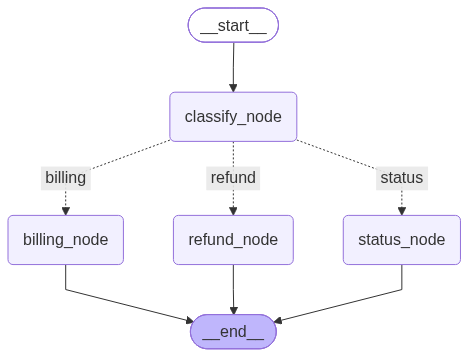

In [10]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel
# Literal is used for define the predefined set of strings that a function can return or a variable can hold.
from typing import Literal

class TicketState(BaseModel):
    issue: str = ""
    category: Literal["billing", "refund", "status"] = "status"
    response: list = []

# A LLM can be used to classify the issue into one of the predefined categories.
# In this example, we are using a simple rule-based approach to classify the issue based on keywords in the issue text.
def classify (state: TicketState) -> TicketState:
    issue = state.issue.lower()
    if "payment" in issue or "amount" in issue:
        state.category = "billing"
    elif "refund" in issue or "cancel" in issue:
        state.category = "refund"
    else:
        state.category = "status"

    return state

def handle_billing_node(state: TicketState) -> TicketState:
    print("Billing Related Issue")
    state.response = f"Issue Resolved for {state.category}"
    return state

def handle_refund_node(state: TicketState) -> TicketState:
    print("Refund Related Issue")
    state.response = f"Issue Resolved for {state.category}"
    return state

def handle_status_node(state: TicketState) -> TicketState:
    print("Status Related Issue")
    state.response = f"Issue Resolved for {state.category}"
    return state

# This is not my node
def router_logic(state: TicketState) -> Literal["billing", "refund", "status"]:
    return state.category

graph = StateGraph(TicketState)
graph.add_node("classify_node", classify)
graph.add_node("billing_node", handle_billing_node)
graph.add_node("refund_node", handle_refund_node)
graph.add_node("status_node", handle_status_node)

graph.add_edge(START, "classify_node")
graph.add_conditional_edges(
    "classify_node",
    router_logic, {
        "billing": "billing_node",
        "refund": "refund_node",
        "status": "status_node"
    })
graph.add_edge("billing_node", END)
graph.add_edge("refund_node", END)
graph.add_edge("status_node", END)

final_graph = graph.compile()
final_graph

In [11]:
res = final_graph.invoke({"issue": "I am waiting for my refund"})
res

Refund Related Issue


{'issue': 'I am waiting for my refund',
 'category': 'refund',
 'response': 'Issue Resolved for refund'}

#### 5. memory - checkpointer

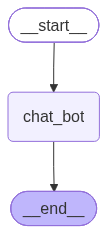

In [12]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel
from typing import Annotated
from langgraph.checkpoint.memory import InMemorySaver

class ChatState(BaseModel):
    messages: Annotated[list, add_messages]

def chat_bot(state: ChatState):
    state.messages = [llm.invoke(state.messages)]
    return state

graph = StateGraph(ChatState)

graph.add_node("chat_bot", chat_bot)
graph.add_edge(START, "chat_bot")
graph.add_edge("chat_bot", END)

# Create Graph without memory saver.
# The LLM can not remember the previous messages in the conversation.
# It will only respond to the current message.
# final_graph = graph.compile()

# Create Graph with memory saver.
memory = InMemorySaver()
final_graph = graph.compile(checkpointer=memory)
final_graph


In [13]:
# res1 = final_graph.invoke(
#     {"messages": [{"role": "user", "content": "PM of India ?"}]},
#     {"configurable": {"thread_id": "1"}}
# )
# answer1 = res1["messages"][-1].content
# print("Answer 1: ", answer1)

res2 = final_graph.invoke(
    {"messages": [{"role": "user", "content": "His age ?"}]},
    {"configurable": {"thread_id": "1"}} # thread id should be same as previous message to remember the previous messages in the conversation.
)
answer2 = res2["messages"][-1].content
print("Answer 2: ", answer2)

res3 = final_graph.invoke(
    {"messages": [{"role": "user", "content": "His age ?"}]},
    {"configurable": {"thread_id": "2"}} # thread id should be same as previous message to remember the previous messages in the conversation.
)
answer3 = res3["messages"][-1].content
print("Answer 3: ", answer3)

Answer 2:  I’m not sure who “he” refers to. Could you let me know which person you’re asking about?
Answer 3:  As of today (2026‑10‑11), he is **47 years, 3 months, and 19 days** old.


In [14]:
# pip install langgraph-checkpoint-sqlite

In [15]:
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver

connection = sqlite3.connect("chatbot_sqlite3_memory.db", check_same_thread=False)
sqlite3_memory = SqliteSaver(connection)
sqlite3_memory.setup()


In [16]:
sqlite3_graph = graph.compile(checkpointer=sqlite3_memory)

# res3 = sqlite3_graph.invoke(
#     {"messages": [{"role": "user", "content": "PM of India ?"}]},
#     {"configurable": {"thread_id": "3"}}
# )
# answer3 = res3["messages"][-1].content
# print("Answer 3: ", answer3) 

res4 = sqlite3_graph.invoke(
    {"messages": [{"role": "user", "content": "His age ?"}]},
    {"configurable": {"thread_id": "3"}} # thread id should be same as previous message to remember the previous messages in the conversation.
)
answer4 = res4["messages"][-1].content
print("Answer 4: ", answer4)

# res3 = sqlite3_graph.invoke(
#     {"messages": [{"role": "user", "content": "His age ?"}]},
#     {"configurable": {"thread_id": "4"}} # thread id should be same as previous message to remember the previous messages in the conversation.
# )
# answer3 = res3["messages"][-1].content
# print("Answer 3: ", answer3)

Answer 4:  **Narendra Modi is 76 years old** (as of 11 October 2026).  

Let me know if there’s anything else you’d like to know!


#### 6. Agents and Tools - ToolNodes

In [17]:
#### We need to define the tools
from langchain.tools import tool
import requests

@tool
def weather_tool(city_name: str) -> str:
    """
        Get the real-time weather information for a given city.
        Args:
            city_name (str): The name of the city for which to retrieve weather information.
        Returns:
            str: A string containing the weather information for the specified city.
    """

    weather_api_key = os.getenv("WEATHER_API_KEY")
    WEATHER_API_URL = f"https://api.openweathermap.org/data/2.5/weather?q={city_name}&appid={weather_api_key}"
    res = requests.get(WEATHER_API_URL)

    if res.status_code == 200:
        return res.json()
    
    return "Unable to find weather for this city"

@tool
def calculate(expression: str):
    """
        Execute the math equation : Ex, '4 * 4 - 4'
    """

    try:
        return eval(expression)
    except:
        return "Please provide correct expression"

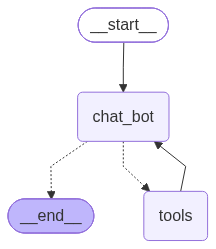

In [18]:
from typing import Annotated
from pydantic import BaseModel
from langchain_core.messages import HumanMessage
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import tools_condition, ToolNode

class AgentState(BaseModel):
    messages: Annotated[list, add_messages]

tools = [weather_tool, calculate]
llm_with_tools = llm.bind_tools(tools)

def chat_bot(state: AgentState):
    res = llm_with_tools.invoke(state.messages)
    state.messages = [res]
    return state

tool_node = ToolNode(tools)

graph = StateGraph(AgentState)
graph.add_node("chat_bot", chat_bot)
graph.add_node("tools", tool_node)

graph.add_edge(START, "chat_bot")
graph.add_conditional_edges("chat_bot", tools_condition)
graph.add_edge("tools", "chat_bot")
graph.add_edge("chat_bot", END)

final_graph = graph.compile(checkpointer=sqlite3_memory)
final_graph

 

In [19]:
res = final_graph.invoke(
    {"messages":
        [ HumanMessage(content="What is the temperature in bengalru ?")]
    },
    {
        "configurable": {"thread_id": "agent-conv-1"}
    }
)

# For debugging
# for msg in res["messages"]:
#     msg.pretty_print()

ans = res["messages"][-1].content
ans
print(ans)

The current temperature in Bengaluru (sometimes spelled “bengalru”) is **301.9 K**:

- **≈ 28.7 °C**  
- **≈ 84.6 °F**

Let me know if you’d like more details or a different location!
